# Proyek Analisis Data: E-Commerce Public Dataset
- **Nama:** Nur Ihsan
- **Email:** nurihsanazhari@gmail.com
- **ID Dicoding:** nurihsannn

## Menentukan Pertanyaan Bisnis
- **Pertanyaan 1 (Konsentrasi Kota):** Di 10 kota (city) manakah terdapat pelanggan unik terbanyak beserta persentase kontribusinya terhadap total pelanggan unik pada seluruh data historis Olist, sehingga tim logistik dapat memprioritaskan hub distribusi pada perencanaan kuartal berikutnya?
  - *Specific*: Fokus pada 10 kota dengan pelanggan unik terbanyak.
  - *Measurable*: Jumlah pelanggan unik dan persentase kontribusi terhadap total pelanggan unik.
  - *Action-Oriented*: Hasilnya menentukan urutan prioritas lokasi hub/gudang distribusi.
  - *Relevant*: Hub yang dekat dengan konsentrasi pelanggan membantu mempercepat pengiriman e-commerce.
  - *Time-bound*: Data historis seluruh periode dataset, untuk keputusan perencanaan kuartal berikutnya.

- **Pertanyaan 2 (Konsentrasi Negara Bagian):** Bagaimana perbandingan jumlah dan persentase pelanggan unik di 5 negara bagian (state) teratas pada seluruh data historis Olist, sehingga tim marketing dapat membagi budget promosi secara proporsional dengan ukuran pasar tiap wilayah pada perencanaan kuartal berikutnya?
  - *Specific*: Fokus pada 5 negara bagian dengan pelanggan unik terbanyak.
  - *Measurable*: Jumlah pelanggan unik dan persentase kontribusinya.
  - *Action-Oriented*: Tim marketing dapat membagi persentase budget ads sesuai ukuran pasar tiap state.
  - *Relevant*: Berkaitan langsung dengan alokasi dana kampanye pemasaran.
  - *Time-bound*: Data historis seluruh periode dataset, untuk perencanaan kuartal berikutnya.

## Import Semua Packages/Library yang Digunakan

In [110]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

## Data Wrangling

### Gathering Data

In [111]:
df = pd.read_csv("olist_customers_dataset.csv")
print(list(df.columns))

['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']


**Insight:**
- Tabel `customers` berisi 5 kolom: `customer_id`, `customer_unique_id`, `customer_zip_code_prefix`, `customer_city`, dan `customer_state`.
- `customer_id` bersifat unik **per pesanan**, sedangkan `customer_unique_id` mengidentifikasi **orang yang sama** lintas pesanan. Karena itu, untuk menghitung "pelanggan", kolom yang dipakai adalah `customer_unique_id`.

### Assessing Data

In [112]:
print("--- Info Dataset ---")
customers_df.info()

print("\n--- Missing Values ---")
print(customers_df.isna().sum())

print(f"\nBaris duplikat persis: {customers_df.duplicated().sum()}")
print(f"Jumlah customer_id unik        : {customers_df['customer_id'].nunique()}")
print(f"Jumlah customer_unique_id unik : {customers_df['customer_unique_id'].nunique()}")
print(f"Baris dengan customer_unique_id berulang: {customers_df['customer_unique_id'].duplicated().sum()}")

--- Info Dataset ---
<class 'pandas.core.frame.DataFrame'>
Index: 67588 entries, 0 to 69247
Data columns (total 6 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   customer_id               67588 non-null  object
 1   customer_unique_id        67588 non-null  object
 2   customer_zip_code_prefix  67588 non-null  object
 3   customer_city             67588 non-null  object
 4   customer_state            67588 non-null  object
 5   region_cluster            67588 non-null  object
dtypes: object(6)
memory usage: 3.6+ MB

--- Missing Values ---
customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
region_cluster              0
dtype: int64

Baris duplikat persis: 0
Jumlah customer_id unik        : 67588
Jumlah customer_unique_id unik : 67588
Baris dengan customer_unique_id berulang: 0


In [113]:
lokasi = customers_df.groupby("customer_unique_id").agg(
    n_kota=("customer_city", "nunique"),
    n_state=("customer_state", "nunique"),
)
print(f"customer_unique_id dengan >1 kota  : {(lokasi['n_kota'] > 1).sum()}")
print(f"customer_unique_id dengan >1 state : {(lokasi['n_state'] > 1).sum()}")

panjang_zip = customers_df["customer_zip_code_prefix"].astype(str).str.len()
print("\nPanjang digit customer_zip_code_prefix:")
print(panjang_zip.value_counts())

print("\nContoh nama kota (format asli):", customers_df["customer_city"].head(5).tolist())
print("Jumlah state unik:", customers_df["customer_state"].nunique())

customer_unique_id dengan >1 kota  : 0
customer_unique_id dengan >1 state : 0

Panjang digit customer_zip_code_prefix:
customer_zip_code_prefix
5    67588
Name: count, dtype: int64

Contoh nama kota (format asli): ['Franca', 'Sao Bernardo Do Campo', 'Sao Paulo', 'Mogi Das Cruzes', 'Campinas']
Jumlah state unik: 27


**Insight & Identifying Problem:**
- **Missing value:** tidak ada. Seluruh 69.248 baris terisi lengkap di semua kolom.
- **Duplicate data:** tidak ada baris yang duplikat persis. Terdapat 69.248 `customer_id` tetapi hanya 67.588 `customer_unique_id`, artinya 1.660 baris adalah *repeat order* oleh pelanggan yang sama. **Solusi:** hapus duplikasi berdasarkan `customer_unique_id`.
- **Inconsistent value (lokasi):** 49 `customer_unique_id` tercatat di lebih dari satu kota, dan 18 di antaranya di lebih dari satu state. Tabel tidak punya kolom waktu sehingga alamat terbaru tidak dapat ditentukan. **Solusi:** pertahankan catatan pertama.
- **Invalid/inconsistent value (format):** kode pos sudah 5 digit pada seluruh baris, sehingga tidak perlu diperbaiki. Kode pos dibaca sebagai string agar angka nol di depan tidak hilang.
- **Inconsistent value (format kota):** nama kota seluruhnya huruf kecil dan tanpa aksen (mis. `sao paulo`). **Solusi:** standarkan menjadi *Title Case*.
- **Keterbatasan data:** tidak ada kolom tanggal, sehingga analisis tidak dapat difilter per periode.
- **Keterbatasan sumber:** file `olist_customers_dataset.csv` yang dibaca hanya berisi 69.248 dari 99.441 baris asli karena baris rusak dilewati (`on_bad_lines="skip"`). Angka pada analisis ini berlaku untuk subset tersebut.

### Cleaning Data

In [114]:
print(f"Total baris sebelum dibersihkan: {customers_df.shape[0]}")

customers_df = customers_df.drop_duplicates(subset="customer_unique_id", keep="first").copy()

customers_df["customer_zip_code_prefix"] = (
    customers_df["customer_zip_code_prefix"].astype(str).str.zfill(5)
)

customers_df["customer_city"] = customers_df["customer_city"].str.title()

print(f"Total baris sesudah dibersihkan: {customers_df.shape[0]}")
print(f"Duplikasi customer_unique_id tersisa: {customers_df['customer_unique_id'].duplicated().sum()}")
print(f"Kode pos bukan 5 digit tersisa: {(customers_df['customer_zip_code_prefix'].str.len() != 5).sum()}")
customers_df.head()

Total baris sebelum dibersihkan: 67588
Total baris sesudah dibersihkan: 67588
Duplikasi customer_unique_id tersisa: 0
Kode pos bukan 5 digit tersisa: 0


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,region_cluster
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,Franca,SP,Sudeste
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,09790,Sao Bernardo Do Campo,SP,Sudeste
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,01151,Sao Paulo,SP,Sudeste
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,08775,Mogi Das Cruzes,SP,Sudeste
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,Campinas,SP,Sudeste


**Insight:** setelah cleaning, data berisi 67.588 baris dan setiap baris mewakili satu pelanggan unik. Format kode pos dan nama kota sudah seragam.

## Exploratory Data Analysis (EDA)

In [115]:
total_customers = customers_df["customer_unique_id"].nunique()

top_cities = (
    customers_df.groupby("customer_city")["customer_unique_id"].nunique()
    .sort_values(ascending=False).reset_index(name="customer_count")
)
top_cities["percentage (%)"] = round(top_cities["customer_count"] / total_customers * 100, 2)

top_states = (
    customers_df.groupby("customer_state")["customer_unique_id"].nunique()
    .sort_values(ascending=False).reset_index(name="customer_count")
)
top_states["percentage (%)"] = round(top_states["customer_count"] / total_customers * 100, 2)

print(f"Total pelanggan unik: {total_customers:,}")
print(f"Jumlah kota: {customers_df['customer_city'].nunique():,} | Jumlah state: {customers_df['customer_state'].nunique()}")

print("\n--- Top 10 Kota ---")
display(top_cities.head(10))

print("\n--- Top 5 Negara Bagian ---")
display(top_states.head(5))

top10_sum = top_cities.head(10)["customer_count"].sum()
print(f"\nTotal 10 kota teratas: {top10_sum:,} pelanggan ({top10_sum / total_customers * 100:.2f}%)")
sp_rj = top_cities.head(2)["customer_count"].sum()
print(f"Sao Paulo + Rio De Janeiro: {sp_rj:,} pelanggan ({sp_rj / total_customers * 100:.2f}%)")
print(f"Rasio Sao Paulo : Rio De Janeiro = {top_cities.loc[0, 'customer_count'] / top_cities.loc[1, 'customer_count']:.2f}x")
top5_sum = top_states.head(5)["customer_count"].sum()
print(f"Total 5 negara bagian teratas: {top5_sum:,} pelanggan ({top5_sum / total_customers * 100:.2f}%)")
top3_sum = top_states.head(3)["customer_count"].sum()
print(f"SP + RJ + MG: {top3_sum:,} pelanggan ({top3_sum / total_customers * 100:.2f}%)")

Total pelanggan unik: 67,588
Jumlah kota: 3,682 | Jumlah state: 27

--- Top 10 Kota ---


,customer_city,customer_count,percentage (%)
0,Sao Paulo,10589,15.67
1,Rio De Janeiro,4647,6.88
2,Belo Horizonte,1899,2.81
3,Brasilia,1470,2.17
4,Curitiba,1030,1.52
5,Campinas,969,1.43
6,Porto Alegre,917,1.36
7,Salvador,859,1.27
8,Guarulhos,781,1.16
9,Sao Bernardo Do Campo,644,0.95



--- Top 5 Negara Bagian ---


,customer_state,customer_count,percentage (%)
0,SP,28329,41.91
1,RJ,8750,12.95
2,MG,7964,11.78
3,RS,3680,5.44
4,PR,3434,5.08



Total 10 kota teratas: 23,805 pelanggan (35.22%)
Sao Paulo + Rio De Janeiro: 15,236 pelanggan (22.54%)
Rasio Sao Paulo : Rio De Janeiro = 2.28x
Total 5 negara bagian teratas: 52,157 pelanggan (77.17%)
SP + RJ + MG: 45,043 pelanggan (66.64%)


**Insight**
- **Berdasarkan kota:** dari 67.588 pelanggan unik, Sao Paulo memiliki basis terbesar, yaitu 10.589 pelanggan (15,67%), sekitar 2,28 kali Rio De Janeiro di urutan kedua (4.647; 6,88%). Belo Horizonte di urutan ketiga memiliki 1.899 pelanggan (2,81%). Sepuluh kota teratas menyumbang 23.805 pelanggan (35,22%).
- **Berdasarkan negara bagian:** SP mendominasi dengan 28.329 pelanggan (41,91%), disusul RJ 8.750 (12,95%), MG 7.964 (11,78%), RS 3.680 (5,44%), dan PR 3.434 (5,08%). Lima negara bagian teratas mencakup 52.157 pelanggan (77,17%), dan tiga teratas saja 66,64%.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Di 10 kota (city) manakah terdapat pelanggan unik terbanyak beserta persentase kontribusinya terhadap total pelanggan unik pada seluruh data historis Olist, sehingga tim logistik dapat memprioritaskan hub distribusi pada perencanaan kuartal berikutnya?

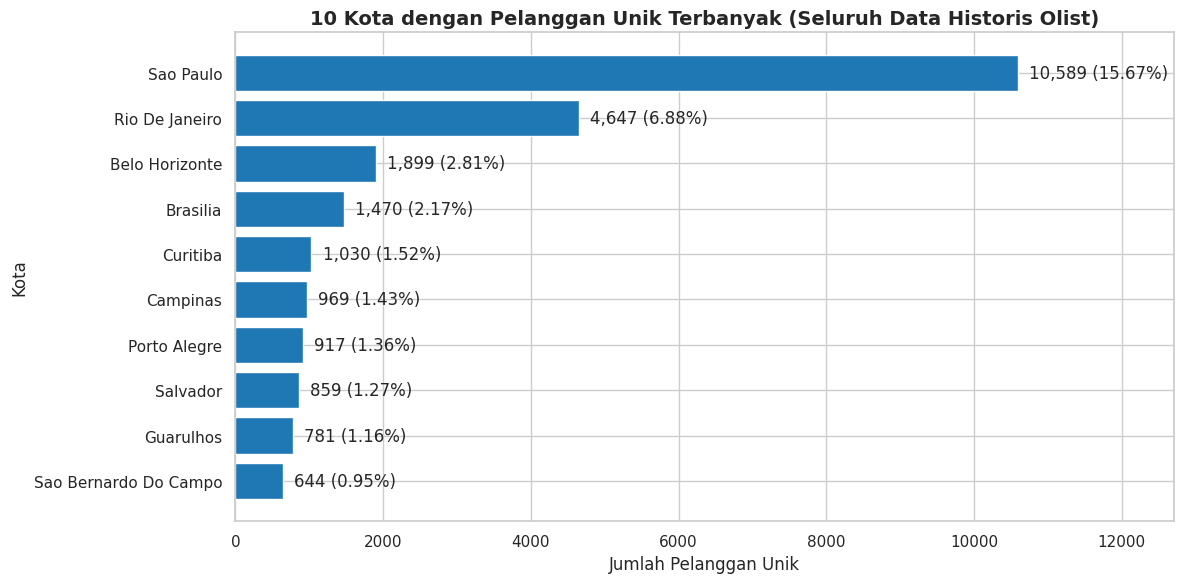

Total 10 kota teratas : 23,805 pelanggan (35.22%)
Sao Paulo : Rio De Janeiro    = 2.28x
Sao Paulo : Belo Horizonte    = 5.58x


In [116]:
top10_cities = top_cities.head(10).sort_values("customer_count")  # ascending agar terbesar di atas

fig, ax = plt.subplots(figsize=(12, 6))
bars = ax.barh(top10_cities["customer_city"], top10_cities["customer_count"], color="#1f77b4")
for bar, cnt, pct in zip(bars, top10_cities["customer_count"], top10_cities["percentage (%)"]):
    ax.text(bar.get_width() + 150, bar.get_y() + bar.get_height() / 2,
            f"{cnt:,} ({pct:.2f}%)", va="center")
ax.set_xlim(0, top10_cities["customer_count"].max() * 1.2)
ax.set_title("10 Kota dengan Pelanggan Unik Terbanyak (Seluruh Data Historis Olist)",
             fontsize=14, fontweight="bold")
ax.set_xlabel("Jumlah Pelanggan Unik")
ax.set_ylabel("Kota")
plt.tight_layout()
plt.show()

sp = top_cities.loc[0, "customer_count"]
rj = top_cities.loc[1, "customer_count"]
bh = top_cities.loc[2, "customer_count"]
top10_sum = top_cities.head(10)["customer_count"].sum()
print(f"Total 10 kota teratas : {top10_sum:,} pelanggan ({top10_sum / total_customers * 100:.2f}%)")
print(f"Sao Paulo : Rio De Janeiro    = {sp / rj:.2f}x")
print(f"Sao Paulo : Belo Horizonte    = {sp / bh:.2f}x")

**Insight**

Sao Paulo berada jauh di depan dengan 10.589 pelanggan unik (15,67%), sekitar 2,28 kali Rio De Janeiro (4.647; 6,88%) dan sekitar 5,58 kali Belo Horizonte (1.899; 2,81%). Sepuluh kota teratas menyumbang 23.805 pelanggan (35,22%). Sao Paulo dan Rio De Janeiro gabungannya 15.236 pelanggan (22,54%), sehingga keduanya menjadi kandidat utama prioritas hub, diikuti Belo Horizonte.

### Pertanyaan 2: Bagaimana perbandingan jumlah dan persentase pelanggan unik di 5 negara bagian (state) teratas pada seluruh data historis Olist, sehingga tim marketing dapat membagi budget promosi secara proporsional dengan ukuran pasar tiap wilayah pada perencanaan kuartal berikutnya?

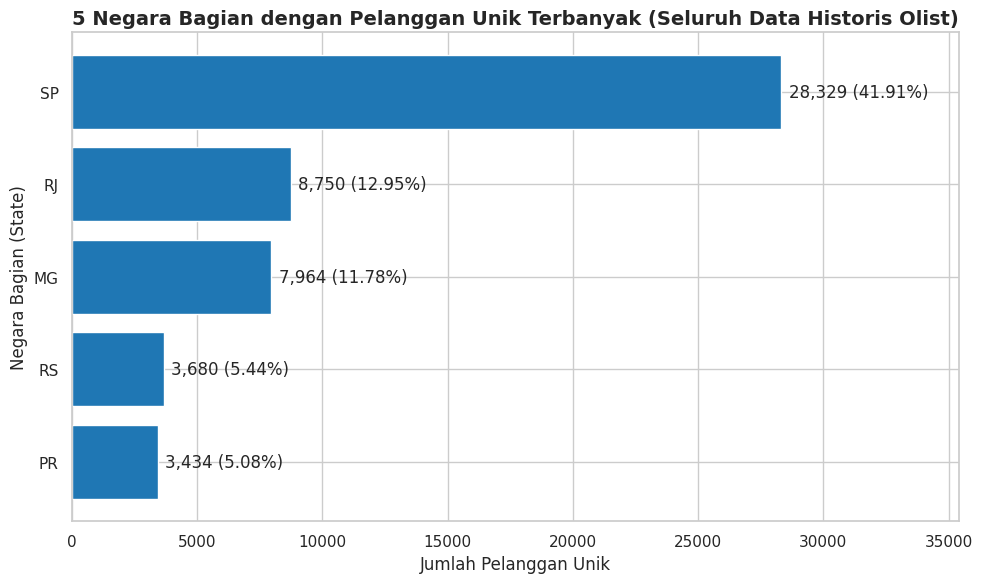

Total 5 negara bagian teratas : 52,157 pelanggan (77.17%)
SP : RJ = 3.24x
SP : MG = 3.56x


In [117]:
top5_states = top_states.head(5).sort_values("customer_count")

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(top5_states["customer_state"], top5_states["customer_count"], color="#1f77b4")
for bar, cnt, pct in zip(bars, top5_states["customer_count"], top5_states["percentage (%)"]):
    ax.text(bar.get_width() + 300, bar.get_y() + bar.get_height() / 2,
            f"{cnt:,} ({pct:.2f}%)", va="center")
ax.set_xlim(0, top5_states["customer_count"].max() * 1.25)
ax.set_title("5 Negara Bagian dengan Pelanggan Unik Terbanyak (Seluruh Data Historis Olist)",
             fontsize=14, fontweight="bold")
ax.set_xlabel("Jumlah Pelanggan Unik")
ax.set_ylabel("Negara Bagian (State)")
plt.tight_layout()
plt.show()

sp_s = top_states.loc[0, "customer_count"]
rj_s = top_states.loc[1, "customer_count"]
mg_s = top_states.loc[2, "customer_count"]
top5_sum = top_states.head(5)["customer_count"].sum()
print(f"Total 5 negara bagian teratas : {top5_sum:,} pelanggan ({top5_sum / total_customers * 100:.2f}%)")
print(f"SP : RJ = {sp_s / rj_s:.2f}x")
print(f"SP : MG = {sp_s / mg_s:.2f}x")

**Insight**

SP memiliki 28.329 pelanggan unik (41,91%), sekitar 3,24 kali RJ (8.750; 12,95%) dan sekitar 3,56 kali MG (7.964; 11,78%). RS (3.680; 5,44%) dan PR (3.434; 5,08%) berukuran hampir sama dan masing-masing kurang dari separuh MG. Lima negara bagian teratas mencakup 77,17% pelanggan, dan SP+RJ+MG saja 66,64%. Jika budget promosi dibagi proporsional dengan ukuran pasar, tiga negara bagian teratas layak mendapat porsi terbesar, sedangkan RS dan PR berada di tier kedua.

### Manual Grouping: Segmentasi Region Makro

State yang belum terpetakan: 0


,region_cluster,customer_count,percentage (%)
0,Sudeste,46425,68.69
1,Sul,9535,14.11
2,Nordeste,6401,9.47
3,Centro-Oeste,3955,5.85
4,Norte,1272,1.88


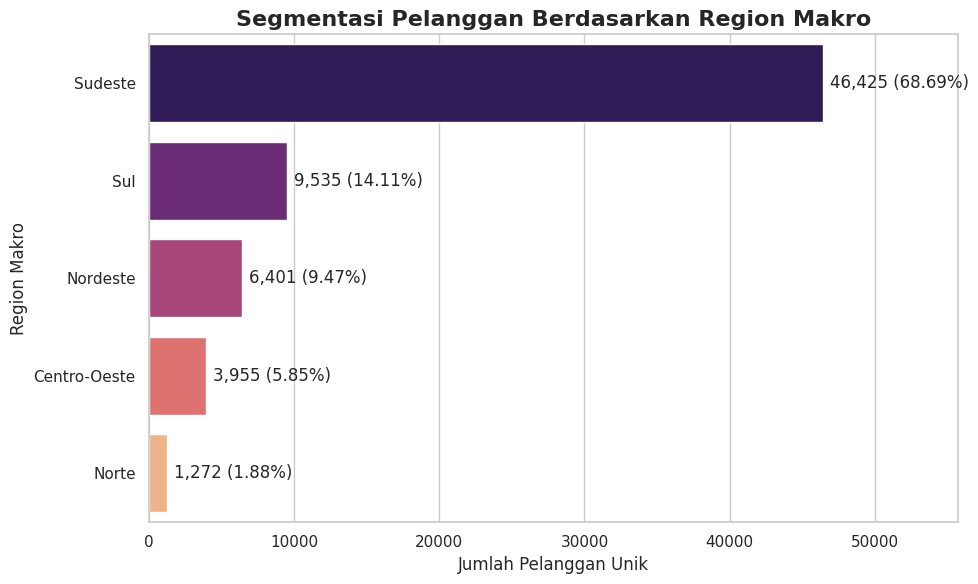

In [118]:
brazil_regions = {
    "AM": "Norte", "RR": "Norte", "AP": "Norte", "PA": "Norte", "TO": "Norte", "RO": "Norte", "AC": "Norte",
    "MA": "Nordeste", "PI": "Nordeste", "CE": "Nordeste", "RN": "Nordeste", "PE": "Nordeste",
    "PB": "Nordeste", "SE": "Nordeste", "AL": "Nordeste", "BA": "Nordeste",
    "MT": "Centro-Oeste", "MS": "Centro-Oeste", "GO": "Centro-Oeste", "DF": "Centro-Oeste",
    "SP": "Sudeste", "RJ": "Sudeste", "ES": "Sudeste", "MG": "Sudeste",
    "PR": "Sul", "RS": "Sul", "SC": "Sul",
}
customers_df["region_cluster"] = customers_df["customer_state"].map(brazil_regions)
print("State yang belum terpetakan:", customers_df["region_cluster"].isna().sum())

region_counts = (
    customers_df.groupby("region_cluster")["customer_unique_id"].nunique()
    .sort_values(ascending=False).reset_index(name="customer_count")
)
region_counts["percentage (%)"] = round(region_counts["customer_count"] / total_customers * 100, 2)
display(region_counts)

plt.figure(figsize=(10, 6))
ax = sns.barplot(
    x="customer_count", y="region_cluster", hue="region_cluster",
    data=region_counts, palette="magma", legend=False,
)
for i, (cnt, pct) in enumerate(zip(region_counts["customer_count"], region_counts["percentage (%)"])):
    ax.text(cnt + region_counts["customer_count"].max() * 0.01, i, f"{cnt:,} ({pct:.2f}%)", va="center")
ax.set_xlim(0, region_counts["customer_count"].max() * 1.2)
plt.title("Segmentasi Pelanggan Berdasarkan Region Makro", fontsize=16, fontweight="bold")
plt.xlabel("Jumlah Pelanggan Unik")
plt.ylabel("Region Makro")
plt.tight_layout()
plt.show()

In [119]:
es_count = customers_df.loc[customers_df["customer_state"] == "ES", "customer_unique_id"].nunique()
print(f"ES (Espírito Santo): {es_count:,} pelanggan ({es_count / total_customers * 100:.2f}%)")

ES (Espírito Santo): 1,382 pelanggan (2.04%)


**Insight**

Region Sudeste berkontribusi 68,69% pelanggan (46.425), jauh di atas Sul 14,11% (9.535), Nordeste 9,47% (6.401), Centro-Oeste 5,85% (3.955), dan Norte 1,88% (1.272). Angka 68,69% terdiri atas SP, RJ, dan MG (66,64%) ditambah ES (1.382; 2,04%). Pasar sangat terkonsentrasi di Tenggara, sedangkan Norte adalah region dengan pelanggan paling sedikit.

### Binning: Segmentasi Kota Berdasarkan Ukuran Basis Pelanggan

,city_tier,jumlah_kota,jumlah_pelanggan,% kota,% pelanggan
0,1-10,3011,8466,81.78,12.53
1,11-50,485,10899,13.17,16.13
2,51-100,91,6427,2.47,9.51
3,101-1000,90,22161,2.44,32.79
4,>1000,5,19635,0.14,29.05


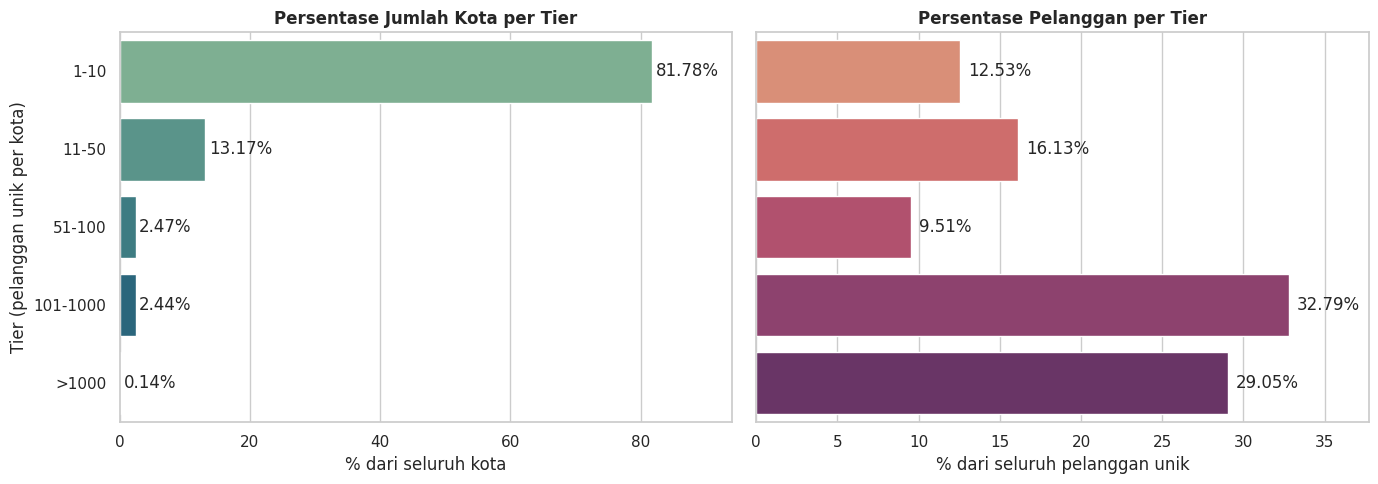

In [120]:
bins = [0, 10, 50, 100, 1000, float("inf")]
labels = ["1-10", "11-50", "51-100", "101-1000", ">1000"]
top_cities["city_tier"] = pd.cut(top_cities["customer_count"], bins=bins, labels=labels)

tier_summary = top_cities.groupby("city_tier", observed=True).agg(
    jumlah_kota=("customer_city", "count"),
    jumlah_pelanggan=("customer_count", "sum"),
).reset_index()
tier_summary["city_tier"] = tier_summary["city_tier"].astype(str)
tier_summary["% kota"] = round(tier_summary["jumlah_kota"] / tier_summary["jumlah_kota"].sum() * 100, 2)
tier_summary["% pelanggan"] = round(tier_summary["jumlah_pelanggan"] / total_customers * 100, 2)
display(tier_summary)

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
sns.barplot(x="% kota", y="city_tier", hue="city_tier", data=tier_summary, palette="crest", order=labels, legend=False, ax=axes[0])
axes[0].set_title("Persentase Jumlah Kota per Tier", fontweight="bold")
axes[0].set_xlabel("% dari seluruh kota")
axes[0].set_ylabel("Tier (pelanggan unik per kota)")
sns.barplot(x="% pelanggan", y="city_tier", hue="city_tier", data=tier_summary, palette="flare", order=labels, legend=False, ax=axes[1])
axes[1].set_title("Persentase Pelanggan per Tier", fontweight="bold")
axes[1].set_xlabel("% dari seluruh pelanggan unik")
axes[1].set_ylabel("")
for ax, col in zip(axes, ["% kota", "% pelanggan"]):
    for i, lab in enumerate(labels):
        v = tier_summary.loc[tier_summary["city_tier"] == lab, col].iloc[0]
        ax.text(v + 0.5, i, f"{v:.2f}%", va="center")
    ax.set_xlim(0, tier_summary[col].max() * 1.15)
plt.tight_layout()
plt.show()

**Insight**

Distribusi kota sangat timpang. Hanya 5 kota (0,14% dari seluruh kota) yang memiliki lebih dari 1.000 pelanggan, tetapi menyumbang 29,05% pelanggan. Sebaliknya, 3.011 kota (81,78%) hanya memiliki 1-10 pelanggan dan secara total 12,53% pelanggan. Pasar terpusat di segelintir kota besar, sementara ribuan kota kecil membentuk *long tail* yang sulit dilayani dengan hub tersendiri.

## Conclusion & Recommendation

**Kesimpulan:**
- **Pertanyaan 1:** Konsentrasi pelanggan terbesar berada di Sao Paulo (10.589; 15,67%), Rio De Janeiro (4.647; 6,88%), dan Belo Horizonte (1.899; 2,81%). Sepuluh kota teratas mewakili 35,22% pelanggan; Sao Paulo dan Rio De Janeiro saja 22,54%. Analisis binning menunjukkan 81,78% kota hanya memiliki 1-10 pelanggan.
- **Pertanyaan 2:** Lima negara bagian teratas adalah SP (28.329; 41,91%), RJ (8.750; 12,95%), MG (7.964; 11,78%), RS (3.680; 5,44%), dan PR (3.434; 5,08%), total 77,17% pelanggan. SP, RJ, dan MG bersama-sama 66,64%.

**Rekomendasi Action Item:**
- **Prioritas hub logistik:** jadikan Sao Paulo dan Rio De Janeiro prioritas pertama (gabungan 22,54% pelanggan), lalu Belo Horizonte. Lengkapi dengan data waktu dan biaya pengiriman sebelum keputusan final.
- **Alokasi budget promosi:** gunakan proporsi pelanggan sebagai titik awal, sekitar 66,6% untuk SP, RJ, dan MG, dan sekitar 10,5% untuk RS dan PR. Evaluasi dengan data biaya akuisisi per wilayah.
- **Uji region berpotensi tumbuh:** Norte (1,88%) dan Centro-Oeste (5,85%) masih kecil. Sisihkan porsi kecil budget untuk uji kampanye dan pantau pertumbuhannya.
- **Layani kota kecil tanpa hub:** karena 81,78% kota hanya memiliki 1-10 pelanggan, layani melalui hub regional atau kemitraan kurir.

**Catatan keterbatasan:** dataset tidak memuat tanggal, nilai transaksi, maupun data pengiriman. Selain itu, file yang dibaca hanya berisi 69.248 dari 99.441 baris asli, sehingga angka ini berlaku untuk subset tersebut. Unduh ulang file dari Kaggle untuk hasil resmi.

### Menyimpan Data untuk Dashboard

In [121]:
main_df = customers_df[["customer_unique_id", "customer_city", "customer_state", "region_cluster"]]
main_df.to_csv("main_data.csv", index=False)
print(f"Sukses! main_data.csv dibuat: {main_df.shape[0]} baris.")

Sukses! main_data.csv dibuat: 67588 baris.
